# Experiment 4 — Forward Chaining Inference Engine
## Data-Driven Reasoning / Animal Identification (ZOOKEEPER)

**Aim:** Implement a forward chaining inference engine and use it to identify animals from observed features, following the experiment brief.

## 1. Theory

Forward chaining is **data-driven inference**. The engine starts with known facts and repeatedly applies rules whose antecedents are satisfied.

For a rule

\[
R_i:\quad A_1 \land A_2 \land \cdots \land A_k 
ightarrow B
\]

the rule is applicable when every antecedent is present in working memory and the conclusion is not already present.

At each cycle:

1. Compute the conflict set.
2. Select a rule according to the specified rule order.
3. Fire it.
4. Add its conclusion to working memory.
5. Record the rule identifier.
6. Repeat until the goal is identified or no rule can fire.

The important distinction from backward chaining is that the engine is driven by **what is known**, not by a requested goal.

The firing sequence also forms a raw derivation/explanation trace. For example:

`striped + mammal → carnivore → tiger`

shows how intermediate conclusions are built incrementally.

## 2. Algorithm

### First-applicable-rule forward chaining

```text
WM ← initial observed facts
firing_sequence ← []

repeat:
    conflict_set ← all rules whose conditions are satisfied
                    and whose conclusion is not in WM

    if conflict_set is empty:
        stop

    selected_rule ← first rule in conflict_set
    add selected_rule.conclusion to WM
    record selected_rule.id

until required animal is identified

return WM, firing_sequence, identification
```

### All-applicable-rules variant

For Exercise 3, every currently applicable rule is fired in one cycle. Newly derived facts are used in the **next** cycle, which makes the comparison fair and keeps the cycle semantics explicit.

In [1]:
# Imports and display configuration
from dataclasses import dataclass
from typing import List, Tuple, Optional, Dict, Iterable, Any
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 140)
print("Libraries loaded successfully.")

Libraries loaded successfully.


## 3. Rule Representation

A rule has:
- an identifier,
- a list of positive/negative conditions,
- one conclusion,
- and a human-readable description.

Negative conditions are represented explicitly as `NOT fact`. This is **not** a closed-world assumption: absence of `carnivore` does not automatically mean `NOT carnivore`. The negative fact must be supplied or derived explicitly.

In [2]:
@dataclass(frozen=True)
class Rule:
    rule_id: str
    conditions: Tuple[str, ...]
    conclusion: str
    description: str = ""

def is_negative(condition: str) -> bool:
    return condition.startswith("NOT ")

def positive_literal(condition: str) -> str:
    return condition[4:] if is_negative(condition) else condition

def conditions_satisfied(rule: Rule, facts: set) -> bool:
    for cond in rule.conditions:
        if is_negative(cond):
            # Explicit negation: "NOT x" is satisfied only when the negative fact exists.
            if cond not in facts:
                return False
        else:
            if cond not in facts:
                return False
    return True

def applicable(rule: Rule, facts: set) -> bool:
    return conditions_satisfied(rule, facts) and rule.conclusion not in facts

def format_rule(rule: Rule) -> str:
    lhs = " AND ".join(rule.conditions)
    return f"{rule.rule_id}: IF {lhs} THEN {rule.conclusion}"

print("Rule representation ready.")

Rule representation ready.


## 4. ZOOKEEPER-Style Knowledge Base

The source brief does not provide the literal rule table, so the following compact rule base is an **operationalization for the experiment**. It is designed to demonstrate the exact mechanism requested.

### Core classification rules
- `R1`: hair → mammal
- `R2`: feathers → bird
- `R3`: mammal + eats meat → carnivore
- `R4`: mammal + hoofed → ungulate
- `R5`: mammal + carnivore + striped → tiger
- `R6`: mammal + ungulate + long neck + long legs → giraffe
- `R7`: mammal + ungulate + black stripes + NOT carnivore → zebra

The tiger chain intentionally demonstrates intermediate abstraction:

`hair → mammal → carnivore → tiger`

The giraffe and zebra rules directly exercise the additional features requested in Exercise 1.

In [3]:
RULES = [
    Rule("R1", ("hair",), "mammal", "Hair implies mammal."),
    Rule("R2", ("feathers",), "bird", "Feathers imply bird."),
    Rule("R3", ("mammal", "eats meat"), "carnivore", "A mammal that eats meat is a carnivore."),
    Rule("R4", ("mammal", "hoofed"), "ungulate", "A hoofed mammal is an ungulate."),
    Rule("R5", ("mammal", "carnivore", "striped"), "tiger", "Striped mammal carnivore is identified as tiger."),
    Rule("R6", ("mammal", "ungulate", "long neck", "long legs"), "giraffe",
         "Ungulate mammal with long neck and long legs is identified as giraffe."),
    Rule("R7", ("mammal", "ungulate", "black stripes", "NOT carnivore"), "zebra",
         "Ungulate mammal with black stripes and explicit NOT carnivore is identified as zebra."),
]

rules_df = pd.DataFrame([
    {"Rule": r.rule_id, "Conditions": " AND ".join(r.conditions), "Conclusion": r.conclusion, "Meaning": r.description}
    for r in RULES
])
rules_df

,Rule,Conditions,Conclusion,Meaning
0,R1,hair,mammal,Hair implies mammal.
1,R2,feathers,bird,Feathers imply bird.
2,R3,mammal AND eats meat,carnivore,A mammal that eats meat is a carnivore.
3,R4,mammal AND hoofed,ungulate,A hoofed mammal is an ungulate.
4,R5,mammal AND carnivore AND striped,tiger,Striped mammal carnivore is identified as tiger.
5,R6,mammal AND ungulate AND long neck AND long legs,giraffe,Ungulate mammal with long neck and long legs is identified as giraffe.
6,R7,mammal AND ungulate AND black stripes AND NOT carnivore,zebra,Ungulate mammal with black stripes and explicit NOT carnivore is identified ...


## 5. Forward Chaining Engine

The engine below records:
- cycle number,
- conflict set,
- selected/fired rule(s),
- newly derived fact(s),
- working-memory size,
- and whether an identification was reached.

The first-applicable version follows the assignment's instruction to select the first rule according to the given rule order.

In [4]:
def conflict_set(rules: List[Rule], facts: set) -> List[Rule]:
    return [r for r in rules if applicable(r, facts)]

def identify_from_facts(facts: set, rules: List[Rule], animal_names: Iterable[str]) -> Optional[str]:
    # Rule-order independent identification check: if an animal fact exists, return it.
    animal_names = list(animal_names)
    found = [a for a in animal_names if a in facts]
    return found[0] if found else None

def forward_chain_first(
    initial_facts: Iterable[str],
    rules: List[Rule],
    animal_names: Iterable[str] = ("tiger", "giraffe", "zebra"),
    max_cycles: int = 100
) -> Dict[str, Any]:
    facts = set(initial_facts)
    trace = []
    firing_sequence = []

    for cycle in range(1, max_cycles + 1):
        cs = conflict_set(rules, facts)
        identified_before = identify_from_facts(facts, rules, animal_names)

        if not cs:
            trace.append({
                "cycle": cycle, "conflict_set": [],
                "fired": None, "new_fact": None,
                "wm_size": len(facts), "identified": identified_before
            })
            break

        selected = cs[0]
        facts.add(selected.conclusion)
        firing_sequence.append(selected.rule_id)

        identified_after = identify_from_facts(facts, rules, animal_names)
        trace.append({
            "cycle": cycle,
            "conflict_set": [r.rule_id for r in cs],
            "fired": selected.rule_id,
            "new_fact": selected.conclusion,
            "wm_size": len(facts),
            "identified": identified_after
        })

        if identified_after is not None:
            break

    return {
        "initial_facts": set(initial_facts),
        "final_facts": facts,
        "firing_sequence": firing_sequence,
        "identified": identify_from_facts(facts, rules, animal_names),
        "trace": pd.DataFrame(trace)
    }

def forward_chain_all(
    initial_facts: Iterable[str],
    rules: List[Rule],
    animal_names: Iterable[str] = ("tiger", "giraffe", "zebra"),
    max_cycles: int = 100
) -> Dict[str, Any]:
    facts = set(initial_facts)
    trace = []
    firing_sequence = []

    for cycle in range(1, max_cycles + 1):
        cs = conflict_set(rules, facts)
        identified_before = identify_from_facts(facts, rules, animal_names)

        if not cs:
            trace.append({
                "cycle": cycle, "conflict_set": [r.rule_id for r in cs],
                "fired": [], "new_facts": [], "wm_size": len(facts),
                "identified": identified_before
            })
            break

        # Snapshot the conflict set. All rules applicable at the start of the cycle fire.
        fired_rules = cs.copy()
        new_facts = []
        for r in fired_rules:
            if r.conclusion not in facts:
                facts.add(r.conclusion)
                new_facts.append(r.conclusion)
                firing_sequence.append(r.rule_id)

        identified_after = identify_from_facts(facts, rules, animal_names)
        trace.append({
            "cycle": cycle,
            "conflict_set": [r.rule_id for r in cs],
            "fired": [r.rule_id for r in fired_rules],
            "new_facts": new_facts,
            "wm_size": len(facts),
            "identified": identified_after
        })

        # Stop once an identification is reached, as in the assignment.
        if identified_after is not None:
            break

    return {
        "initial_facts": set(initial_facts),
        "final_facts": facts,
        "firing_sequence": firing_sequence,
        "identified": identify_from_facts(facts, rules, animal_names),
        "trace": pd.DataFrame(trace)
    }

print("Both inference-engine variants are ready.")

Both inference-engine variants are ready.


## 6. Main Demonstration — Tiger

Observed features:

- `hair`
- `eats meat`
- `striped`

Expected derivation:

`R1: hair → mammal`  
`R3: mammal + eats meat → carnivore`  
`R5: mammal + carnivore + striped → tiger`

This gives the characteristic multi-step forward-chaining sequence `R1 → R3 → R5`.

In [5]:
tiger_case = forward_chain_first(
    {"hair", "eats meat", "striped"},
    RULES
)

print("Initial WM:", sorted(tiger_case["initial_facts"]))
print("Firing sequence:", " → ".join(tiger_case["firing_sequence"]))
print("Final WM:", sorted(tiger_case["final_facts"]))
print("Identification:", tiger_case["identified"])
tiger_case["trace"]

Initial WM: ['eats meat', 'hair', 'striped']
Firing sequence: R1 → R3 → R5
Final WM: ['carnivore', 'eats meat', 'hair', 'mammal', 'striped', 'tiger']
Identification: tiger


,cycle,conflict_set,fired,new_fact,wm_size,identified
0,1,[R1],R1,mammal,4,NaN
1,2,[R3],R3,carnivore,5,NaN
2,3,[R5],R5,tiger,6,tiger


In [6]:
# Explanation-oriented derivation trace
def explanation_trace(result: Dict[str, Any]) -> pd.DataFrame:
    rows = []
    trace = result["trace"]
    for _, row in trace.iterrows():
        if row["fired"] is not None:
            rule = next(r for r in RULES if r.rule_id == row["fired"])
            rows.append({
                "Cycle": int(row["cycle"]),
                "Rule": rule.rule_id,
                "Conditions": " AND ".join(rule.conditions),
                "Derived": row["new_fact"],
                "WM size after firing": int(row["wm_size"])
            })
    return pd.DataFrame(rows)

explanation_trace(tiger_case)

,Cycle,Rule,Conditions,Derived,WM size after firing
0,1,R1,hair,mammal,4
1,2,R3,mammal AND eats meat,carnivore,5
2,3,R5,mammal AND carnivore AND striped,tiger,6


### Conflict-set evolution

The conflict set is recomputed after every firing. Thus, adding `mammal` can enable `R3`, and adding `carnivore` can enable `R5`.

In [7]:
tiger_conflict = tiger_case["trace"].copy()
tiger_conflict["Conflict set"] = tiger_conflict["conflict_set"].apply(lambda x: ", ".join(x) if x else "∅")
tiger_conflict[["cycle", "Conflict set", "fired", "new_fact", "wm_size", "identified"]]

,cycle,Conflict set,fired,new_fact,wm_size,identified
0,1,R1,R1,mammal,4,NaN
1,2,R3,R3,carnivore,5,NaN
2,3,R5,R5,tiger,6,tiger


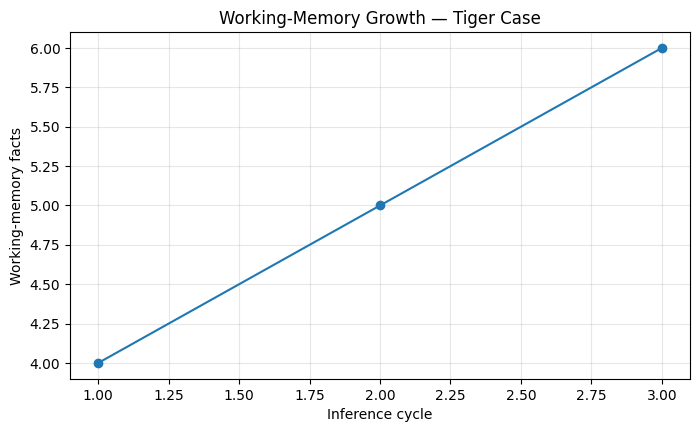

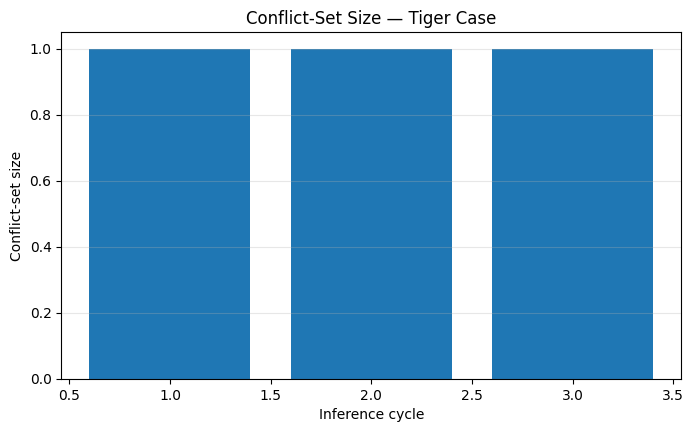

In [8]:
# Plot 1: working-memory growth during the tiger derivation
plt.figure(figsize=(8, 4.5))
plt.plot(tiger_case["trace"]["cycle"], tiger_case["trace"]["wm_size"], marker="o")
plt.xlabel("Inference cycle")
plt.ylabel("Working-memory facts")
plt.title("Working-Memory Growth — Tiger Case")
plt.grid(True, alpha=0.3)
plt.show()

# Plot 2: conflict-set size
conf_sizes = tiger_case["trace"]["conflict_set"].apply(len)
plt.figure(figsize=(8, 4.5))
plt.bar(tiger_case["trace"]["cycle"], conf_sizes)
plt.xlabel("Inference cycle")
plt.ylabel("Conflict-set size")
plt.title("Conflict-Set Size — Tiger Case")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

## 7. Exercise 1 — Add Tiger, Giraffe, and Zebra

The exercise specifically asks for:
- **tiger**
- **giraffe**: long neck, long legs
- **zebra**: black stripes, **not carnivore**

The zebra case uses explicit negation. This is important: `NOT carnivore` is treated as a fact, not inferred merely because `carnivore` is absent.

In [9]:
EXERCISE_1_CASES = {
    "Tiger": {"hair", "eats meat", "striped"},
    "Giraffe": {"hair", "hoofed", "long neck", "long legs"},
    "Zebra": {"hair", "hoofed", "black stripes", "NOT carnivore"},
}

exercise1_results = {}
summary_rows = []

for label, facts in EXERCISE_1_CASES.items():
    result = forward_chain_first(facts, RULES)
    exercise1_results[label] = result
    summary_rows.append({
        "Animal": label,
        "Initial facts": ", ".join(sorted(facts)),
        "Firing sequence": " → ".join(result["firing_sequence"]),
        "Identified": result["identified"],
        "Final WM size": len(result["final_facts"]),
    })

exercise1_summary = pd.DataFrame(summary_rows)
exercise1_summary

,Animal,Initial facts,Firing sequence,Identified,Final WM size
0,Tiger,"eats meat, hair, striped",R1 → R3 → R5,tiger,6
1,Giraffe,"hair, hoofed, long legs, long neck",R1 → R4 → R6,giraffe,7
2,Zebra,"NOT carnivore, black stripes, hair, hoofed",R1 → R4 → R7,zebra,7


In [10]:
# Show detailed traces for all three animals
for label, result in exercise1_results.items():
    print(f"\n{'='*18} {label.upper()} {'='*18}")
    print("Firing sequence:", " → ".join(result["firing_sequence"]) or "none")
    print("Final facts:", sorted(result["final_facts"]))
    print("Identification:", result["identified"])
    display(result["trace"])


================== TIGER ==================
Firing sequence: R1 → R3 → R5
Final facts: ['carnivore', 'eats meat', 'hair', 'mammal', 'striped', 'tiger']
Identification: tiger


,cycle,conflict_set,fired,new_fact,wm_size,identified
0,1,[R1],R1,mammal,4,NaN
1,2,[R3],R3,carnivore,5,NaN
2,3,[R5],R5,tiger,6,tiger



================== GIRAFFE ==================
Firing sequence: R1 → R4 → R6
Final facts: ['giraffe', 'hair', 'hoofed', 'long legs', 'long neck', 'mammal', 'ungulate']
Identification: giraffe


,cycle,conflict_set,fired,new_fact,wm_size,identified
0,1,[R1],R1,mammal,5,NaN
1,2,[R4],R4,ungulate,6,NaN
2,3,[R6],R6,giraffe,7,giraffe



================== ZEBRA ==================
Firing sequence: R1 → R4 → R7
Final facts: ['NOT carnivore', 'black stripes', 'hair', 'hoofed', 'mammal', 'ungulate', 'zebra']
Identification: zebra


,cycle,conflict_set,fired,new_fact,wm_size,identified
0,1,[R1],R1,mammal,5,NaN
1,2,[R4],R4,ungulate,6,NaN
2,3,[R7],R7,zebra,7,zebra


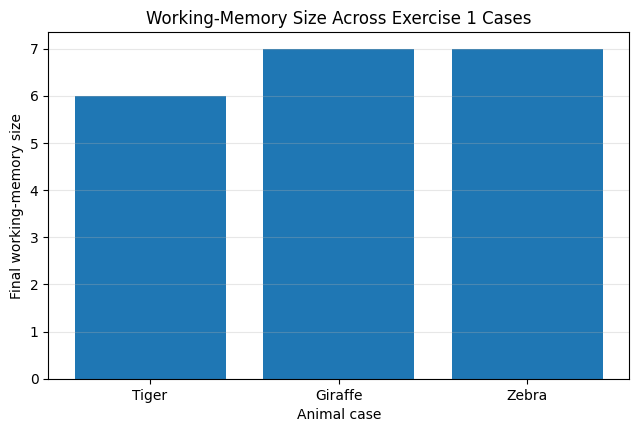

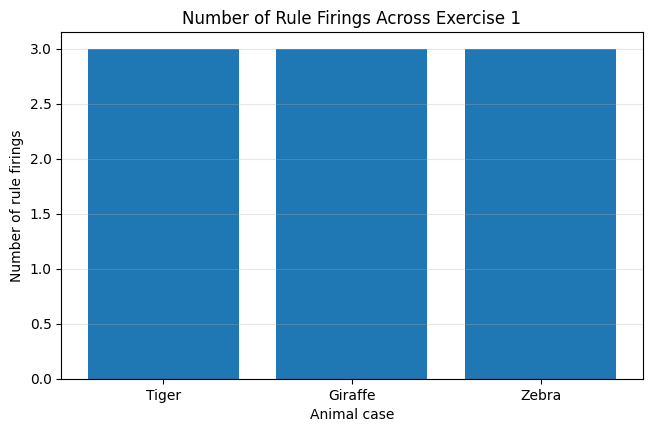

In [11]:
# Plot 3: number of derived facts by animal
plt.figure(figsize=(7.5, 4.5))
plt.bar(exercise1_summary["Animal"], exercise1_summary["Final WM size"])
plt.xlabel("Animal case")
plt.ylabel("Final working-memory size")
plt.title("Working-Memory Size Across Exercise 1 Cases")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

# Plot 4: firing-sequence length
plt.figure(figsize=(7.5, 4.5))
plt.bar(exercise1_summary["Animal"], exercise1_summary["Firing sequence"].str.count("R"))
plt.xlabel("Animal case")
plt.ylabel("Number of rule firings")
plt.title("Number of Rule Firings Across Exercise 1")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

## 8. Exercise 2 — No Identification Rule

Give the engine facts that cannot establish a specific animal and report the **most specific class** it can establish.

Test case:

`{hair}`

From `R1`, the engine can establish `mammal`, but no animal-identification rule can fire after that because the remaining distinguishing features are unavailable.

Therefore:
- identified animal: **None**
- most specific established class: **mammal**

This demonstrates the required graceful termination when the conflict set becomes empty.

In [12]:
partial_case = forward_chain_first({"hair"}, RULES)

print("Initial facts:", sorted(partial_case["initial_facts"]))
print("Firing sequence:", " → ".join(partial_case["firing_sequence"]))
print("Final facts:", sorted(partial_case["final_facts"]))
print("Animal identification:", partial_case["identified"])

# Class specificity used for this experiment.
SPECIFICITY_ORDER = ["animal", "vertebrate", "mammal", "bird", "carnivore", "ungulate", "tiger", "giraffe", "zebra"]

def most_specific_class(facts: set) -> Optional[str]:
    present = [x for x in SPECIFICITY_ORDER if x in facts]
    return present[-1] if present else None

print("Most specific class established:", most_specific_class(partial_case["final_facts"]))
display(partial_case["trace"])

Initial facts: ['hair']
Firing sequence: R1
Final facts: ['hair', 'mammal']
Animal identification: None
Most specific class established: mammal


,cycle,conflict_set,fired,new_fact,wm_size,identified
0,1,[R1],R1,mammal,2,None
1,2,[],NaN,NaN,2,None


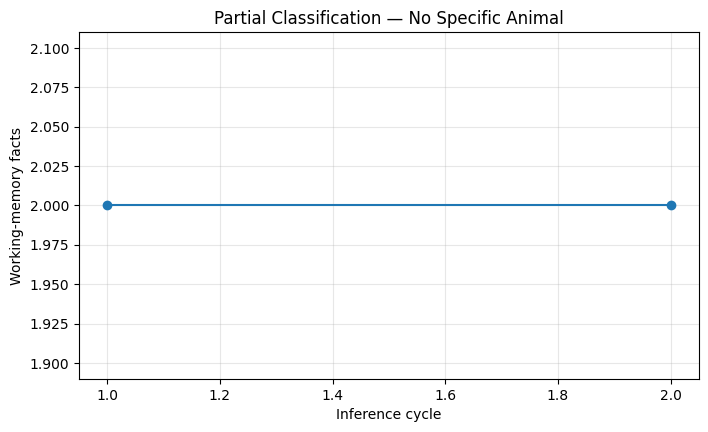

In [13]:
# Plot 5: partial classification process
partial_trace = partial_case["trace"]
plt.figure(figsize=(8, 4.5))
plt.step(partial_trace["cycle"], partial_trace["wm_size"], where="mid", marker="o")
plt.xlabel("Inference cycle")
plt.ylabel("Working-memory facts")
plt.title("Partial Classification — No Specific Animal")
plt.grid(True, alpha=0.3)
plt.show()

## 9. Exercise 3 — First Rule vs All Applicable Rules

To make the difference visible, the rule base is intentionally extended with two independent rules:

- `R8`: hair → warm blooded
- `R9`: hoofed → terrestrial

These rules can be applicable alongside the classification rules. The **first-applicable** engine fires only one rule per cycle, while the **all-applicable** engine fires the entire conflict set from the beginning of that cycle.

This is a comparison of inference strategy, not a change in the underlying knowledge.

In [14]:
RULES_COMPARE = RULES + [
    Rule("R8", ("hair",), "warm blooded", "Hair is used as an additional independent feature."),
    Rule("R9", ("hoofed",), "terrestrial", "Hoofed animals are terrestrial in this toy knowledge base."),
]

compare_facts = {"hair", "hoofed", "long neck", "long legs"}

first_compare = forward_chain_first(compare_facts, RULES_COMPARE)
all_compare = forward_chain_all(compare_facts, RULES_COMPARE)

comparison = pd.DataFrame([
    {
        "Strategy": "First applicable",
        "Firing sequence": " → ".join(first_compare["firing_sequence"]),
        "Cycles": len(first_compare["trace"]),
        "Final WM size": len(first_compare["final_facts"]),
        "Identification": first_compare["identified"],
    },
    {
        "Strategy": "All applicable",
        "Firing sequence": " → ".join(all_compare["firing_sequence"]),
        "Cycles": len(all_compare["trace"]),
        "Final WM size": len(all_compare["final_facts"]),
        "Identification": all_compare["identified"],
    }
])
comparison

,Strategy,Firing sequence,Cycles,Final WM size,Identification
0,First applicable,R1 → R4 → R6,3,7,giraffe
1,All applicable,R1 → R8 → R9 → R4 → R6,3,9,giraffe


In [15]:
print("FIRST-APPLICABLE TRACE")
display(first_compare["trace"])

print("\nALL-APPLICABLE TRACE")
display(all_compare["trace"])

print("\nRule-order effect:")
print("First applicable:", first_compare["firing_sequence"])
print("All applicable:", all_compare["firing_sequence"])

FIRST-APPLICABLE TRACE


,cycle,conflict_set,fired,new_fact,wm_size,identified
0,1,"[R1, R8, R9]",R1,mammal,5,NaN
1,2,"[R4, R8, R9]",R4,ungulate,6,NaN
2,3,"[R6, R8, R9]",R6,giraffe,7,giraffe



ALL-APPLICABLE TRACE


,cycle,conflict_set,fired,new_facts,wm_size,identified
0,1,"[R1, R8, R9]","[R1, R8, R9]","[mammal, warm blooded, terrestrial]",7,NaN
1,2,[R4],[R4],[ungulate],8,NaN
2,3,[R6],[R6],[giraffe],9,giraffe



Rule-order effect:
First applicable: ['R1', 'R4', 'R6']
All applicable: ['R1', 'R8', 'R9', 'R4', 'R6']


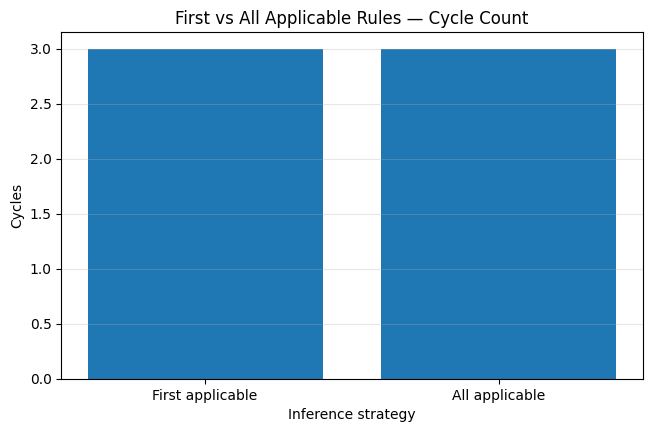

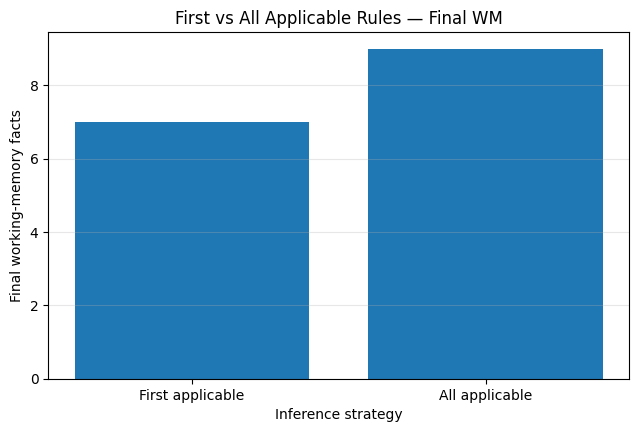

In [16]:
# Plot 6: compare number of cycles
plt.figure(figsize=(7.5, 4.5))
plt.bar(comparison["Strategy"], comparison["Cycles"])
plt.xlabel("Inference strategy")
plt.ylabel("Cycles")
plt.title("First vs All Applicable Rules — Cycle Count")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

# Plot 7: compare final working-memory size
plt.figure(figsize=(7.5, 4.5))
plt.bar(comparison["Strategy"], comparison["Final WM size"])
plt.xlabel("Inference strategy")
plt.ylabel("Final working-memory facts")
plt.title("First vs All Applicable Rules — Final WM")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

## 10. Why the firing sequences differ

With the first-applicable strategy, rule order becomes part of conflict resolution. Only the first matching rule is fired, so other rules may have to wait for later cycles.

With the all-applicable strategy, all rules in the cycle's conflict set fire. Therefore:
- more conclusions can be added per cycle,
- independent consequences appear earlier,
- the firing sequence can be longer even though the number of cycles is smaller,
- and the final closure can be the same when the rules are monotonic and have no contradictory conclusions.

For this experiment, conclusions are only added; they are never removed. This makes the system **monotonic**.

## 11. Additional Sanity Checks

The following checks verify important semantics:
1. A rule cannot fire if a condition is missing.
2. A rule does not fire again after its conclusion is already in working memory.
3. Explicit `NOT carnivore` is required for the zebra rule.
4. Tiger, giraffe, and zebra are correctly identified.
5. The partial case establishes mammal but no specific animal.
6. The all-applicable strategy derives all conclusions that are reachable in its cycles.

In [17]:
# Automated tests
def assert_tests():
    # 1. Missing condition blocks R5.
    assert "tiger" not in forward_chain_first({"hair", "eats meat"}, RULES)["final_facts"]

    # 2. Tiger identification and expected chain.
    t = forward_chain_first({"hair", "eats meat", "striped"}, RULES)
    assert t["identified"] == "tiger"
    assert t["firing_sequence"] == ["R1", "R3", "R5"]

    # 3. Giraffe identification.
    g = forward_chain_first({"hair", "hoofed", "long neck", "long legs"}, RULES)
    assert g["identified"] == "giraffe"
    assert "R6" in g["firing_sequence"]

    # 4. Zebra requires explicit negative fact.
    z_no_neg = forward_chain_first({"hair", "hoofed", "black stripes"}, RULES)
    assert z_no_neg["identified"] is None

    z = forward_chain_first({"hair", "hoofed", "black stripes", "NOT carnivore"}, RULES)
    assert z["identified"] == "zebra"
    assert "R7" in z["firing_sequence"]

    # 5. Partial classification.
    p = forward_chain_first({"hair"}, RULES)
    assert p["identified"] is None
    assert most_specific_class(p["final_facts"]) == "mammal"

    # 6. Refractoriness: no repeated conclusion.
    already_mammal = forward_chain_first({"hair", "mammal"}, RULES)
    assert "R1" not in already_mammal["firing_sequence"]

    # 7. All-applicable variant reaches the same expected animal for a complete case.
    a = forward_chain_all({"hair", "eats meat", "striped"}, RULES_COMPARE)
    assert a["identified"] == "tiger"
    assert set(a["final_facts"]) >= {"hair", "eats meat", "striped", "mammal", "carnivore", "tiger"}

    return "All automated tests passed."

assert_tests()

'All automated tests passed.'

## 12. Complexity Discussion

Let:
- \(R\) = number of rules,
- \(C\) = maximum number of conditions in a rule,
- \(F\) = number of facts eventually derived.

A simple implementation recomputes the conflict set by checking every rule against the fact set. One conflict-set computation costs approximately:

\[
O(RC)
\]

The first-applicable algorithm can fire at most one new conclusion per cycle, so with at most \(F\) useful conclusions its straightforward worst-case behavior is approximately:

\[
O(FRC)
\]

The all-applicable version can add many facts in one cycle and therefore often needs fewer cycles, although it still scans the rule base.

For large production systems, indexing and incremental matching—such as the RETE family of approaches discussed in production-system contexts—can avoid repeatedly checking every rule against every fact.

## 13. Observations

1. The engine starts with observed features and **grows working memory** through rule firing.
2. The conflict set changes after every new conclusion.
3. Intermediate classes such as `mammal`, `carnivore`, and `ungulate` enable increasingly specific conclusions.
4. The tiger example demonstrates a multi-level chain of inference.
5. The giraffe rule uses the requested `long neck` and `long legs` features.
6. The zebra rule demonstrates **explicit negation** through `NOT carnivore`.
7. If the available facts cannot satisfy an animal rule, the engine terminates without inventing an identification.
8. Under first-applicable firing, rule order affects the firing sequence.
9. Under all-applicable firing, independent consequences can be derived in the same cycle.
10. The firing trace is useful as the basis for a later explanation facility because it records which rule produced each conclusion.